# Parcial #2 Machine Learning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from parcial_ml.data import cargar_datos
from parcial_ml.models import ajustar_modelo, predecir
from parcial_ml.analysis import evaluar_grados, calcular_varianza_malla, riesgo_promedio_validacion

# Estilo para las gráficas
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
# Carga de datos
base_path = '../data'
X_train_A, y_train_A = cargar_datos(f'{base_path}/train_A.csv')
X_train_B, y_train_B = cargar_datos(f'{base_path}/train_B.csv')
X_train_C, y_train_C = cargar_datos(f'{base_path}/train_C.csv')
X_val, y_val = cargar_datos(f'{base_path}/validation.csv')

## Ejercicio 1. Complejidad y generalización

### a. Evaluar grados del 1 al 15

In [3]:
grados = list(range(1, 16))
resultados_1, modelos_A = evaluar_grados(X_train_A, y_train_A, X_val, y_val, grados)

df_resultados_1 = pd.DataFrame(resultados_1)
df_resultados_1.columns = ['Grado', 'Riesgo Entrenamiento', 'Riesgo Validación']
display(df_resultados_1)

,Grado,Riesgo Entrenamiento,Riesgo Validación
0,1,0.406777,0.510432
1,2,0.327561,0.441047
2,3,0.120407,0.200026
3,4,0.118253,0.201967
4,5,0.083426,0.161396
5,6,0.082978,0.164074
6,7,0.074472,0.184270
7,8,0.069638,0.189821
8,9,0.069184,0.188407
9,10,0.065834,0.222431


### b. Gráfica de riesgos

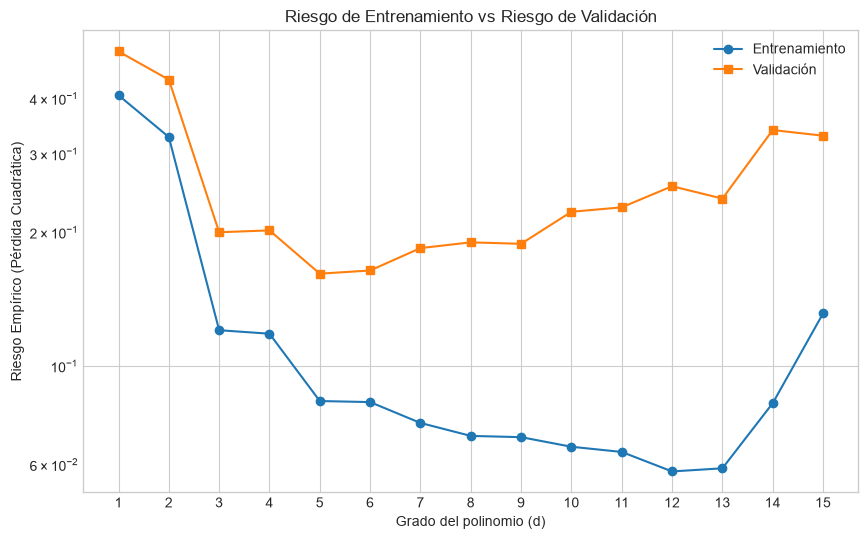

In [4]:
plt.figure(figsize=(10, 6))
plt.plot(df_resultados_1['Grado'], df_resultados_1['Riesgo Entrenamiento'], marker='o', label='Entrenamiento')
plt.plot(df_resultados_1['Grado'], df_resultados_1['Riesgo Validación'], marker='s', label='Validación')
plt.xlabel('Grado del polinomio (d)')
plt.ylabel('Riesgo Empírico (Pérdida Cuadrática)')
plt.title('Riesgo de Entrenamiento vs Riesgo de Validación')
plt.xticks(grados)
plt.legend()
plt.yscale('log') # Escala logarítmica para mejor visualización si los riesgos crecen mucho
plt.savefig('../resultados/ejercicio1_riesgos.png')
plt.show()

### c. Identificar d_train y d_val

In [5]:
d_train = df_resultados_1.loc[df_resultados_1['Riesgo Entrenamiento'].idxmin()]
d_val = df_resultados_1.loc[df_resultados_1['Riesgo Validación'].idxmin()]

print(f"d_train: {int(d_train['Grado'])} con riesgo de {d_train['Riesgo Entrenamiento']:.4f}")
print(f"d_val: {int(d_val['Grado'])} con riesgo de {d_val['Riesgo Validación']:.4f}")

d_train: 12 con riesgo de 0.0579
d_val: 5 con riesgo de 0.1614


### d. Asociaciones:
* **Subajuste:** Grado 2. Riesgo de entrenamiento y validación relativamente altos.
* **Mejor balance:** Grado 6. Riesgo de validación en su punto mínimo o cercano, error de entrenamiento bajo.
* **Sobreajuste:** Grado 15. Riesgo de entrenamiento bajo pero no tan bajo como esparado, el riesgo de validación es elevado debido a la memorización del ruido. Y entonces ¿por qué la gráfica no tiende a 0, más bien el riesgo empírico por qué no tiende a 0? Puede ser por un error de la maquina en si, como un a^15, con el a siendo tan solo digamos 3 es un numero gigante, y pues las maquinas tienen sus limitaciones de memoria, asi que se acumula un error gigante también.

## Ejercicio 2. Sensibilidad a la muestra

### Antes de empezar con los ejercicios, en los 3 datasets ajustamos los modelos

In [6]:
grados_especificos = [2, 6, 15]
modelos_multiples = {2: [], 6: [], 15: []}

# Ajustar modelos en los tres datasets
for d in grados_especificos:
    modelos_multiples[d].append(ajustar_modelo(X_train_A, y_train_A, d))
    modelos_multiples[d].append(ajustar_modelo(X_train_B, y_train_B, d))
    modelos_multiples[d].append(ajustar_modelo(X_train_C, y_train_C, d))

### a. Graficar hipótesis aprendidas y b. Cálculo de V_d

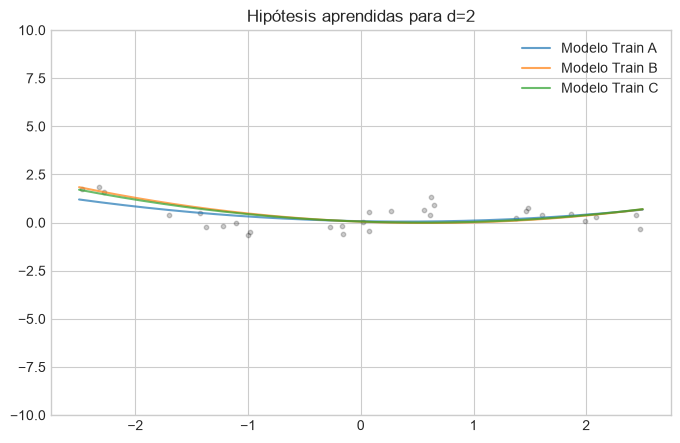

V_2 (Varianza para d=2): 0.0097


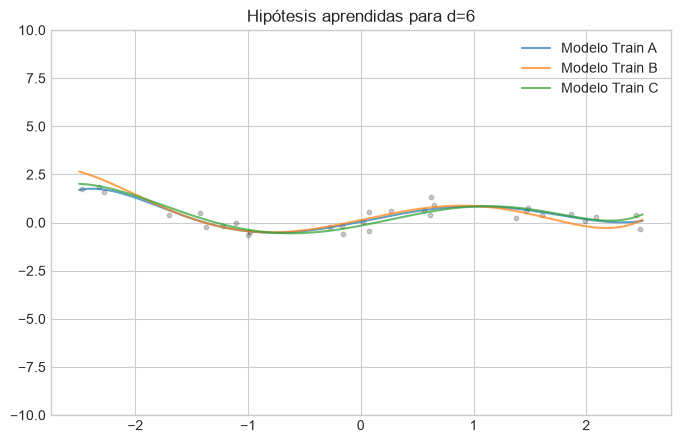

V_6 (Varianza para d=6): 0.0142


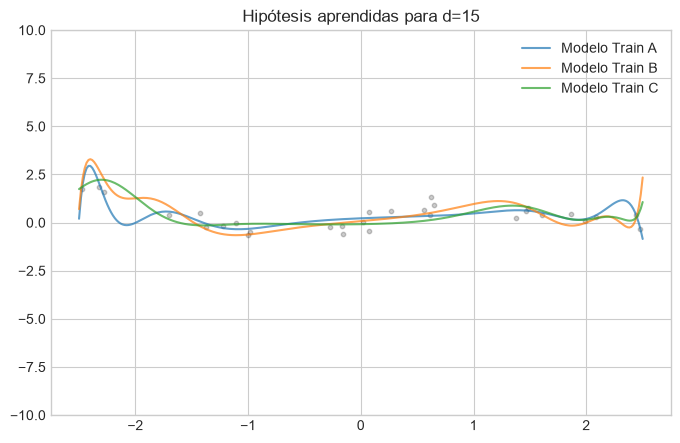

V_15 (Varianza para d=15): 0.0825


In [7]:
V_d_resultados, X_malla, predicciones_malla = calcular_varianza_malla(modelos_multiples, grados_especificos)

for d in grados_especificos:
    plt.figure(figsize=(8, 5))
    preds = predicciones_malla[d]
    
    # Dibujando las predicciones de los 3 modelos
    plt.plot(X_malla, preds[0], label='Modelo Train A', alpha=0.7)
    plt.plot(X_malla, preds[1], label='Modelo Train B', alpha=0.7)
    plt.plot(X_malla, preds[2], label='Modelo Train C', alpha=0.7)
    
    # Gráficos de dispersión para referencia
    plt.scatter(X_train_A, y_train_A, color='black', alpha=0.2, s=10)
    plt.title(f'Hipótesis aprendidas para d={d}')
    plt.legend()
    plt.ylim(-10, 10) # Ajusta estos límites según la distribución real 'y'
    plt.savefig(f'../resultados/ejercicio2_hipotesis_d{d}.png')
    plt.show()
    
    print(f"V_{d} (Varianza para d={d}): {V_d_resultados[d]:.4f}")

### c. Ordenamiento e Identificación
De acuerdo a las salidas de la celda anterior:
1. El valor más bajo de $V_d$ corresponde al modelo más **estable** (en este caso $d=2$). 
2. El valor más alto de $V_d$ corresponde al modelo más **sensible** (en este caso $d=15$).
* Nota: ¿Por qué es mas estable? Por que es más simple, entre menos cosas haga la maquina, mejor, entre más complejo el modelo peor (como con grados mas altos, overfitting, nomas memoriza, no aprende).

### d. Asociaciones
* **Alto Sesgo:** Grado 2 Varianza pequeña, pero no captura la relación completa, riesgo de validación promedio alto.
* **Balance sesgo-varianza:** Grado 6 varianza controlada y el riesgo de validación promedio más bajo.
* **Alta varianza:** Grado 15 Altamente sensible a los datos, produce un $V_d$ gigante y riesgo de validación alto también.
* Nota: El riesgo promedio de validación del grado esta en el ejercicio 3, la conclusión se hizo pues despues del ejercicio 3. 

## Ejercicio 3. Selección del modelo

### a. Calcular riesgo promedio de validación

In [8]:
R_val_promedio = riesgo_promedio_validacion(modelos_multiples, X_val, y_val, grados_especificos)

tabla_final = []
for d in grados_especificos:
    tabla_final.append({
        'Grado': d,
        'R_val(d)': R_val_promedio[d],
        'V_d': V_d_resultados[d]
    })
    
df_final = pd.DataFrame(tabla_final)
display(df_final)

,Grado,R_val(d),V_d
0,2,0.458920,0.009695
1,6,0.164837,0.014151
2,15,0.251828,0.082507


### b. Selección: 
Se selecciona el grado **6**. Presenta el mejor comportamiento conjunto porque su $\overline{R}_{val}(d)$ es el menor de la tabla y su varianza $V_d$ se mantiene controlada en comparación con el grado 15.

### c. Coincidencia: 
No. El grado seleccionado en el literal anterior (6) no coincide con el que produce el menor riesgo de entrenamiento en train_A.csv (que fue 15).


### d. Afirmación del estudiante: 
No. La afirmación no es compatible con los resultados. Aunque el grado 15 alcanzó el menor riesgo de entrenamiento, su $\overline{R}_{val}(15)$ y su $V_{15}$ demuestran una severa falta de generalización por sobreajuste.